In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Cargar dataset de amazon.csv

df_amazon = pd.read_csv('amazon.csv')

In [12]:
df_amazon.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [2]:
# Al contener calificaciones, convertir a float todos los valores numéricos de rating
# Si exielgún valor no numérico, eliminar de rating

# Pasar a float todos los valores numéricos de rating
df_amazon['rating'] = pd.to_numeric(df_amazon['rating'], errors='coerce')    
df_amazon = df_amazon.dropna(subset=['rating'])
df_amazon['rating'] = df_amazon['rating'].astype(float)

<Axes: title={'center': 'Distribución de Ratings en Amazon'}, xlabel='rating'>

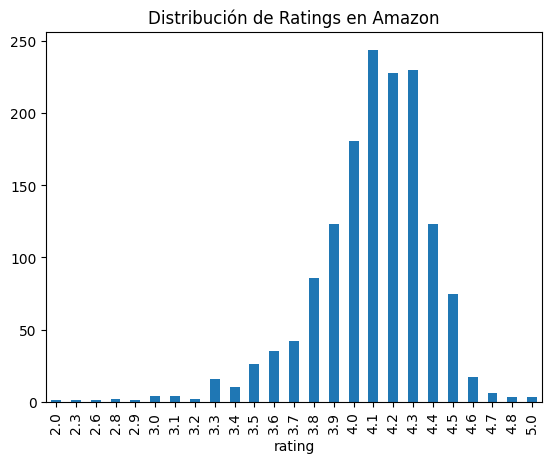

In [3]:
df_amazon["rating"].value_counts().sort_index().plot(kind='bar', title='Distribución de Ratings en Amazon')

In [4]:
# Ahora, turno de cargar train_lite.csv
df_tlite = pd.read_csv("train_lite.csv", names=["polarity", "rev_title", "review_content"])
df_tlite = df_tlite[["polarity", "review_content"]]
df_tlite.head()

,polarity,review_content
0,1,I have tried so many times to get this thing t...
1,1,My baby did NOT like this sling at all. I have...
2,1,All I have to say is who is going put together...
3,1,My chair was received without all of the parts...
4,1,Extremely disappointed that a company as well ...


In [ ]:
df_tlite["polarity"].value_counts()

polarity
1    5042
2    4958
Name: count, dtype: int64

Adosar los archivos .csv

In [6]:
# Obviaremos la normalización
# Adosar los archivos .csv

# Utilizaremos las columnas rating y review_content de df_amazon
df_amazon_subset = df_amazon[["rating", "review_content"]]
# En el caso de df_tlite, renombrar la columna polarity a rating para que coincida
df_tlite = df_tlite.rename(columns={"polarity": "rating"})

In [7]:
def map_amazon_sentiment(r):
    if r >= 4.0:
        return 'Positivo'
    elif r >= 3.0 and r < 4.0:
        return 'Neutro'
    else:
        return 'Negativo'

In [8]:
# Sentiment
df_amazon['sentiment'] = df_amazon['rating'].apply(map_amazon_sentiment)
df_tlite['sentiment'] = df_tlite['rating'].apply(lambda x: 'Positivo' if x == 2 else 'Negativo')

In [9]:
# Seleccionar columnas comunes
df_amazon_clean = df_amazon[['review_content', 'sentiment']]
train_lite_clean = df_tlite[['review_content', 'sentiment']]

# Concatenar
combined_df = pd.concat([df_amazon_clean, train_lite_clean], ignore_index=True)

In [11]:
combined_df["sentiment"].value_counts()

sentiment
Positivo    6068
Negativo    5048
Neutro       348
Name: count, dtype: int64

<Axes: title={'center': 'Distribución de polaridad en las reseñas'}, xlabel='sentiment'>

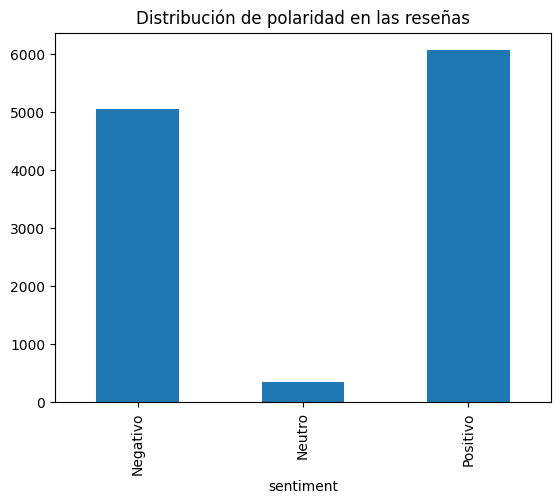

In [16]:
combined_df["sentiment"].value_counts().sort_index().plot(kind='bar', title='Distribución de polaridad en las reseñas')

In [21]:
# Porcentaje de comentarios etiquetados como Positivo, Neutro y Negativo

total_comments = len(combined_df)
sentiment_counts = combined_df['sentiment'].value_counts()
for sentiment, count in sentiment_counts.items():
    percentage = (count / total_comments) * 100
    print(f"{sentiment}: {percentage:.2f}%")
    

Positivo: 52.93%
Negativo: 44.03%
Neutro: 3.04%


Partición del dataset y vectorización

In [27]:
X = combined_df['review_content']
y = combined_df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

Modelo Multinomial de NaiveBayes

In [28]:
# Ahora, modelo Naive Bayes para predecir sentiment a partir de review_content

NB_model = MultinomialNB()
NB_model.fit(X_train_vec, y_train)

y_pred = NB_model.predict(X_test_vec)
# Métricas de evaluación

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Negativo       0.67      0.87      0.75       989
      Neutro       0.86      0.17      0.29        69
    Positivo       0.81      0.65      0.72      1235

    accuracy                           0.73      2293
   macro avg       0.78      0.56      0.59      2293
weighted avg       0.75      0.73      0.72      2293



Modelo de RandomForest

In [ ]:
RF_model = RandomForestClassifier(n_estimators=500, max_depth=20, bootstrap=True, criterion='gini', random_state=0)

RF_model.fit(X_train_vec, y_train)


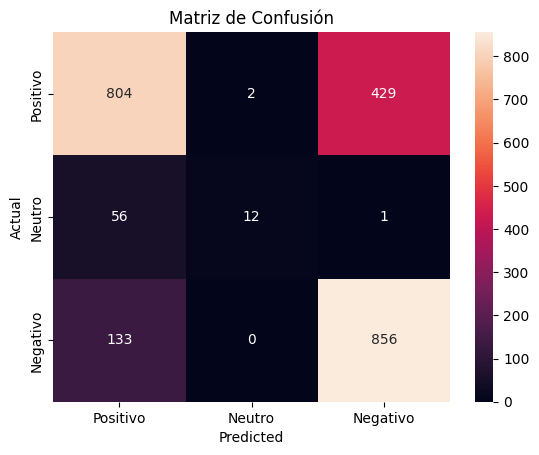

In [ ]:
# Visualizar matriz de confusión

cm = confusion_matrix(y_test, y_pred, labels=['Positivo', 'Neutro', 'Negativo'])
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Positivo', 'Neutro', 'Negativo'], yticklabels=['Positivo', 'Neutro', 'Negativo'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Matriz de Confusión')
plt.show()